# Land Cover Change Explorer

Measures land cover change between two years for any area, using Impact Observatory's 10 m annual land cover maps (2017 onwards), accessed through Microsoft's Planetary Computer. The default example is the Ravi River near Lahore, 2017 vs 2023.

**How to use:** run Setup, enter your area and years in Settings, then click **Runtime → Run all**. Always use Run all after changing settings.

In [73]:
#@title Setup (run this first)
!pip install -q pystac-client==0.9.0 planetary-computer==1.0.0 rioxarray==0.23.0

import pandas as pd
import matplotlib.pyplot as plt
import pystac_client, planetary_computer, rioxarray
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from google.colab import files
from IPython.display import HTML, display
import numpy as np
from pyproj import Transformer

catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1",
    modifier=planetary_computer.sign_inplace)

print("Setup complete.")

def stop(message):
    display(HTML(
        '<div style="background:#fde2e1; color:#8a1c1c; border-left:6px solid #d93025; '
        'padding:12px 16px; font-size:15px; border-radius:4px;">'
        f'<b>⚠️ Please check your settings:</b> {message}</div>'))
    raise ValueError(message)

Setup complete.


In [74]:
#@title Settings: choose your area and years
#@markdown **Area:** a box in degrees. To find coordinates, right-click a point in Google Maps. It shows *latitude, longitude*: latitude is north/south, longitude is east/west.
#@markdown
#@markdown **Years:** the first year must be 2017 or later (the data starts in 2017), and the second must be later than the first. Run this cell to see every year available for your area, listed below it.
place_name = "Ravi River near Lahore"  #@param {type:"string"}
west = 74.18  #@param {type:"number"}
south = 31.52  #@param {type:"number"}
east = 74.40  #@param {type:"number"}
north = 31.72  #@param {type:"number"}
year_before = 2017  #@param {type:"integer"}
year_after = 2023  #@param {type:"integer"}

bbox = [west, south, east, north]
years = [year_before, year_after]

if not (west < east and south < north):
    stop("West must be less than east, and south less than north.")
if (east - west) > 0.5 or (north - south) > 0.5:
    stop("Area too large: keep each side under 0.5 degrees (about 50 km).")
if not 2017 <= year_before < year_after:
    stop("year_before must be 2017 or later, and year_after must be later than year_before.")

all_items = catalog.search(collections=["io-lulc-annual-v02"], bbox=bbox).items()
available = sorted({int(item.id.split("-")[-1]) for item in all_items})
print("Years available for this area:", available)

for year in years:
    if year not in available:
        stop(f"No land cover data for {year} here. Choose from: {available}")

print(f"Settings OK: {place_name}, {year_before} vs {year_after}")


Years available for this area: [2017, 2018, 2019, 2020, 2021, 2022, 2023]
Settings OK: Ravi River near Lahore, 2017 vs 2023


## 1. Find the land cover tile for each year
The global map is split into large tiles that follow the UTM grid. This step finds the tile covering the study area in each chosen year. It stops if the area crosses a tile boundary, because the notebook reads only one tile.

In [75]:
items_by_year = {}
for year in years:
    search = catalog.search(collections=["io-lulc-annual-v02"], bbox=bbox,
                            datetime=f"{year}-01-01/{year}-12-31")
    matches = [item for item in search.items() if item.id.endswith(str(year))]
    if len(matches) == 0:
        stop(f"No land cover data found for {year} in this area.")
    if len(matches) > 1:
        stop(f"Your area crosses a tile boundary ({[m.id for m in matches]}). "
                         "Move or shrink the box so it fits inside one tile.")
    items_by_year[year] = matches[0]
    print(year, "→", matches[0].id)

2017 → 43R-2017
2023 → 43R-2023


## 2. Load and clip
Reads only the study area from each tile, without downloading the whole file. The data stays in its native UTM projection (metres), so each pixel is exactly 10 × 10 m, or 0.01 ha. The clipped maps are also saved as GeoTIFFs in the Files panel, for use in QGIS.

In [76]:
lulc = {}
for year, item in items_by_year.items():
    raster = rioxarray.open_rasterio(item.assets["data"].href)
    lulc[year] = raster.rio.clip_box(*bbox, crs="EPSG:4326")
    lulc[year].rio.to_raster(f"lulc_{year}.tif", compress="deflate")
    print(year, lulc[year].shape, lulc[year].rio.crs)

2017 (1, 2232, 2102) EPSG:32643
2023 (1, 2232, 2102) EPSG:32643


## 3. Check the data
Counts the pixels in each class and confirms both years sit on the same grid. This is required for a pixel-by-pixel comparison: each pixel position must be the same patch of ground in both years. It also flags any pixels with no data (class 0).

In [77]:
present = set()
for year in years:
    counts = pd.Series(lulc[year].values.ravel()).value_counts().sort_index()
    present.update(counts.index)
    print(year, counts.to_dict())

if lulc[year_before].rio.transform() != lulc[year_after].rio.transform():
    stop("The two years are not on the same grid, so they can't be compared.")
print("Same grid: OK")

if 0 in present:
    print("Note: some pixels have no data (class 0). They are left out of the change table.")

2017 {1: 105208, 2: 4952, 4: 80, 5: 2256320, 7: 2092407, 8: 110277, 11: 122420}
2023 {1: 115721, 2: 18240, 4: 39, 5: 2059923, 7: 2341396, 8: 36755, 11: 119590}
Same grid: OK


## 4. Class names and colours
Uses the official Impact Observatory colours. Land cover classes are categories, not a continuous scale, so each class number is given its own colour.

In [78]:
classes = {
    1: ("Water", "#419bdf"),
    2: ("Trees", "#397d49"),
    4: ("Flooded vegetation", "#7a87c6"),
    5: ("Crops", "#e49635"),
    7: ("Built area", "#c4281b"),
    8: ("Bare ground", "#a59b8f"),
    9: ("Snow/ice", "#a8ebff"),
    10: ("Clouds", "#616161"),
    11: ("Rangeland", "#e3e2c3"),
}

codes = list(classes)
cmap = ListedColormap([classes[c][1] for c in codes])
cmap.set_under("white")
norm = BoundaryNorm([c - 0.5 for c in codes] + [codes[-1] + 0.5], cmap.N)

## 5. Maps
Shows both years side by side, with the same colours and extent, so differences are easy to see.

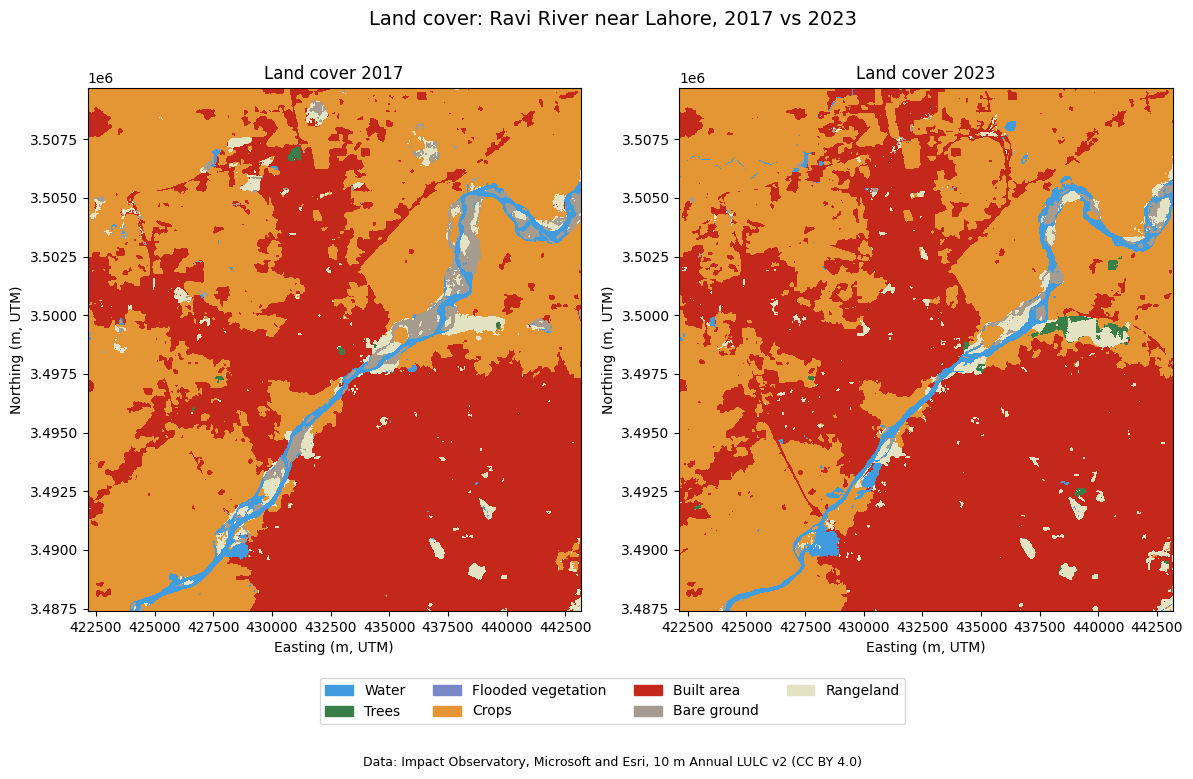

In [79]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

for ax, year in zip(axes, years):
    lulc[year].squeeze().plot.imshow(ax=ax, cmap=cmap, norm=norm, add_colorbar=False)
    ax.set_title(f"Land cover {year}")
    ax.set_xlabel("Easting (m, UTM)")
    ax.set_ylabel("Northing (m, UTM)")
    ax.set_aspect("equal")

legend = [Patch(color=colour, label=name)
          for code, (name, colour) in classes.items() if code in present]
fig.legend(handles=legend, loc="lower center", ncol=4, bbox_to_anchor=(0.5, -0.05))
fig.suptitle(f"Land cover: {place_name}, {year_before} vs {year_after}", fontsize=14)
fig.text(0.5, -0.1, "Data: Impact Observatory, Microsoft and Esri, 10 m Annual LULC v2 (CC BY 4.0)",
         ha="center", fontsize=9)

map_file = f"landcover_{year_before}_{year_after}.png"
plt.savefig(map_file, dpi=200, bbox_inches="tight")
plt.show()

## 6. Change matrix
Compares every pixel's class in the first year with its class in the second. Rows are the first year, columns the second, and values are in hectares. The diagonal is land that didn't change. Pixels with no data in either year are left out.

In [80]:
col_from, col_to = f"from_{year_before}", f"to_{year_after}"

before = lulc[year_before].values.ravel()
after = lulc[year_after].values.ravel()
valid = (before != 0) & (after != 0)

names = {code: name for code, (name, colour) in classes.items()}
change = pd.crosstab(before[valid], after[valid], rownames=[col_from], colnames=[col_to]) / 100
change = change.rename(index=names, columns=names).round(1)
change

to_2023,Water,Trees,Flooded vegetation,Crops,Built area,Bare ground,Rangeland
from_2017,,,,,,,
Water,479.9,0.8,0.1,324.4,26.0,110.0,110.8
Trees,0.0,6.3,0.0,2.0,35.0,0.0,6.2
Flooded vegetation,0.1,0.0,0.3,0.0,0.0,0.0,0.4
Crops,257.9,74.0,0.0,19185.5,2645.4,77.1,323.3
Built area,12.8,13.9,0.0,334.0,20396.6,10.9,155.8
Bare ground,288.3,0.5,0.0,375.6,78.6,139.1,220.7
Rangeland,118.2,86.9,0.0,377.8,232.3,30.5,378.6


## 7. Largest conversions
Turns the matrix into a ranked list of the ten largest changes, leaving out unchanged land.

In [81]:
pairs = change.reset_index().melt(id_vars=col_from, var_name=col_to, value_name="hectares")
conversions = pairs[pairs[col_from] != pairs[col_to]]
conversions = conversions.sort_values("hectares", ascending=False).head(10)
conversions

,from_2017,to_2023,hectares
31,Crops,Built area,2645.4
27,Rangeland,Crops,377.8
26,Bare ground,Crops,375.6
25,Built area,Crops,334.0
21,Water,Crops,324.4
45,Crops,Rangeland,323.3
5,Bare ground,Water,288.3
3,Crops,Water,257.9
34,Rangeland,Built area,232.3
47,Bare ground,Rangeland,220.7


## Accuracy spot-check
Picks random pixels that changed between the two years and lists their coordinates, so the changes can be checked by eye against historical satellite imagery. The random seed is fixed, so the same points are picked every time.

In [82]:
to_lonlat = Transformer.from_crs(lulc[year_before].rio.crs, "EPSG:4326", always_xy=True)

def sample_pixels(from_code, to_code, n, seed):
    before2d = lulc[year_before].squeeze().values
    after2d = lulc[year_after].squeeze().values
    rows, cols = np.where((before2d == from_code) & (after2d == to_code))
    rng = np.random.default_rng(seed)
    pick = rng.choice(len(rows), size=min(n, len(rows)), replace=False)
    xs = lulc[year_before].x.values[cols[pick]]
    ys = lulc[year_before].y.values[rows[pick]]
    lon, lat = to_lonlat.transform(xs, ys)
    return pd.DataFrame({"from": names[from_code], "to": names[to_code],
                         "lat": np.round(lat, 6), "lon": np.round(lon, 6)})

checks = pd.concat([sample_pixels(5, 7, 30, seed=1),
                    sample_pixels(7, 5, 10, seed=2)], ignore_index=True)
checks["real_change"] = ""
checks["notes"] = ""

points_file = f"accuracy_points_{year_before}_{year_after}.csv"
checks.to_csv(points_file, index_label="point")
files.download(points_file)
checks

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,from,to,lat,lon,real_change,notes
0,Crops,Built area,31.615171,74.332358,,
1,Crops,Built area,31.624348,74.202181,,
2,Crops,Built area,31.653425,74.251188,,
3,Crops,Built area,31.711777,74.263278,,
4,Crops,Built area,31.705090,74.246024,,
5,Crops,Built area,31.580474,74.197812,,
6,Crops,Built area,31.636923,74.252480,,
7,Crops,Built area,31.597173,74.290639,,
8,Crops,Built area,31.586902,74.230746,,
9,Crops,Built area,31.717354,74.244975,,


## Runoff curve numbers
Assigns an SCS curve number to each land cover class (standard TR-55 values for average moisture conditions) and calculates the area-weighted curve number and the runoff from an illustrative storm for each year. Soil group B is the main assumption, based on the area's loamy alluvial soils; group C is included as a sensitivity check.

In [83]:
cn_table = {      # class code: (CN for soil group B, CN for soil group C)
    1: (98, 98),  # Water
    2: (55, 70),  # Trees: woods, good condition
    4: (98, 98),  # Flooded vegetation: treated as a saturated surface
    5: (78, 85),  # Crops: row crops, straight row, good condition
    7: (85, 90),  # Built area: residential, 1/8 acre lots (65% impervious)
    8: (86, 91),  # Bare ground: fallow, bare soil
    11: (69, 79), # Rangeland: pasture, fair condition
}
storm_mm = 75     # illustrative storm depth, in mm

def runoff_mm(P, CN):
    S = 25400 / CN - 254
    Ia = 0.2 * S
    return (P - Ia) ** 2 / (P + 0.8 * S) if P > Ia else 0.0

rows = []
for year in years:
    counts = pd.Series(lulc[year].values.ravel()).value_counts()
    area_ha = {code: counts.get(code, 0) / 100 for code in cn_table}
    total = sum(area_ha.values())
    for g, soil in enumerate(["B", "C"]):
        cn = sum(area_ha[c] * cn_table[c][g] for c in cn_table) / total
        q = sum(area_ha[c] * runoff_mm(storm_mm, cn_table[c][g]) for c in cn_table) / total
        rows.append({"year": year, "soil_group": soil,
                     "weighted_CN": round(cn, 1),
                     "runoff_mm": round(q, 1),
                     "runoff_volume_m3": round(q / 1000 * total * 10000)})

runoff = pd.DataFrame(rows)
runoff

,year,soil_group,weighted_CN,runoff_mm,runoff_volume_m3
0,2017,B,81.5,33.9,15892631
1,2017,C,87.5,44.4,20853089
2,2023,B,81.7,34.3,16096631
3,2023,C,87.7,44.8,21016715


### Runoff curves
Plots runoff against rainfall for cropland and built area (soil group B). The gap between the two curves shows how much more of each storm runs off once farmland is built over. The dotted line marks the 75 mm example storm used in the table above.

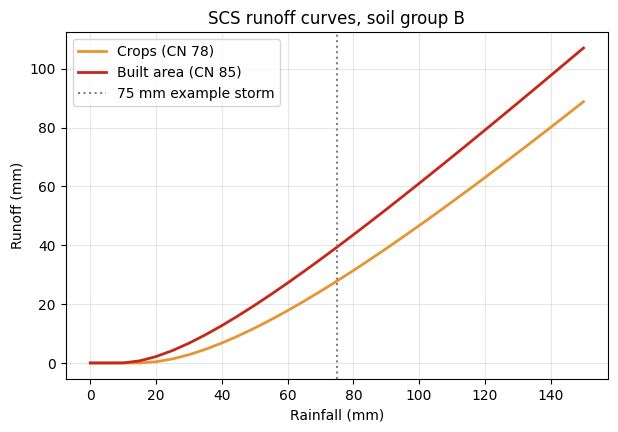

In [84]:
rain = range(0, 151, 5)

fig, ax = plt.subplots(figsize=(7, 4.5))
for code in [5, 7]:
    cn_b = cn_table[code][0]
    ax.plot(rain, [runoff_mm(P, cn_b) for P in rain],
            color=classes[code][1], linewidth=2,
            label=f"{classes[code][0]} (CN {cn_b})")

ax.axvline(storm_mm, color="grey", linestyle=":", label=f"{storm_mm} mm example storm")
ax.set_xlabel("Rainfall (mm)")
ax.set_ylabel("Runoff (mm)")
ax.set_title("SCS runoff curves, soil group B")
ax.grid(alpha=0.3)
ax.legend()

curve_file = f"runoff_curves_{year_before}_{year_after}.png"
plt.savefig(curve_file, dpi=200, bbox_inches="tight")
plt.show()

## 8. Save and download
Saves the map as a PNG and the three tables (change matrix, top conversions and runoff) as CSV files, with the years in each file name, and downloads them.

In [85]:
matrix_file = f"change_matrix_{year_before}_{year_after}_ha.csv"
top_file = f"top_conversions_{year_before}_{year_after}_ha.csv"
runoff_file = f"runoff_cn_{year_before}_{year_after}.csv"

change.to_csv(matrix_file)
conversions.to_csv(top_file, index=False)
runoff.to_csv(runoff_file, index=False)

for f in [map_file, matrix_file, top_file, runoff_file, curve_file]:
    files.download(f)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>